<a href="https://colab.research.google.com/github/evanmccarthy216/h96ahNh2WKWrsjlT/blob/main/customer_happinessl.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!gdown 1KWE3J0uU_sFIJnZ74Id3FDBcejELI7FD -O survey.csv

import pandas as pd
df = pd.read_csv("survey.csv")
df.head()

Downloading...
From: https://drive.google.com/uc?id=1KWE3J0uU_sFIJnZ74Id3FDBcejELI7FD
To: /content/survey.csv
100% 1.91k/1.91k [00:00<00:00, 3.66MB/s]


,Y,X1,X2,X3,X4,X5,X6
0,0,3,3,3,4,2,4
1,0,3,2,3,5,4,3
2,1,5,3,3,3,3,5
3,0,5,4,3,3,3,5
4,0,5,4,3,3,3,5


Y = target attribute (Y) with values indicating 0 (unhappy) and 1 (happy) customers

X1 = my order was delivered on time

X2 = contents of my order was as I expected

X3 = I ordered everything I wanted to order

X4 = I paid a good price for my order

X5 = I am satisfied with my courier

X6 = the app makes ordering easy for me

In [2]:
print(df.shape)
print(df.isnull().sum())
print(df.dtypes)

(126, 7)
Y     0
X1    0
X2    0
X3    0
X4    0
X5    0
X6    0
dtype: int64
Y     int64
X1    int64
X2    int64
X3    int64
X4    int64
X5    int64
X6    int64
dtype: object


The dataset has 126 survey responses with no missing values. All features are integer ratings from 1 to 5, and Y is a binary label (0/1).


In [3]:
print(df["Y"].value_counts())
print(df["Y"].value_counts(normalize=True))

Y
1    69
0    57
Name: count, dtype: int64
Y
1    0.547619
0    0.452381
Name: proportion, dtype: float64


Happy customers = 69  
54.7% are happy

Unhappy customers = 57   
45.2% are unhappy


In [5]:
# summary stats
df.describe()

,Y,X1,X2,X3,X4,X5,X6
count,126.000000,126.000000,126.000000,126.000000,126.000000,126.000000,126.000000
mean,0.547619,4.333333,2.531746,3.309524,3.746032,3.650794,4.253968
std,0.499714,0.800000,1.114892,1.023440,0.875776,1.147641,0.809311
min,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
25%,0.000000,4.000000,2.000000,3.000000,3.000000,3.000000,4.000000
50%,1.000000,5.000000,3.000000,3.000000,4.000000,4.000000,4.000000
75%,1.000000,5.000000,3.000000,4.000000,4.000000,4.000000,5.000000
max,1.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000


In [6]:
for col in ["X1", "X2", "X3", "X4", "X5", "X6"]:
    print(f"\n{col}")
    print(df.groupby(col)["Y"].agg(["mean", "count"]).round(2))


X1
    mean  count
X1             
1   0.00      1
3   0.40     20
4   0.40     40
5   0.69     65

X2
    mean  count
X2             
1   0.52     27
2   0.62     34
3   0.55     42
4   0.41     17
5   0.67      6

X3
    mean  count
X3             
1   0.43      7
2   0.50     14
3   0.47     55
4   0.67     33
5   0.65     17

X4
    mean  count
X4             
1   1.00      2
2   0.20      5
3   0.51     41
4   0.57     53
5   0.60     25

X5
    mean  count
X5             
1   0.29      7
2   0.44     16
3   0.45     22
4   0.56     50
5   0.71     31

X6
    mean  count
X6             
1   1.00      1
2   0.00      1
3   0.30     20
4   0.57     47
5   0.61     57


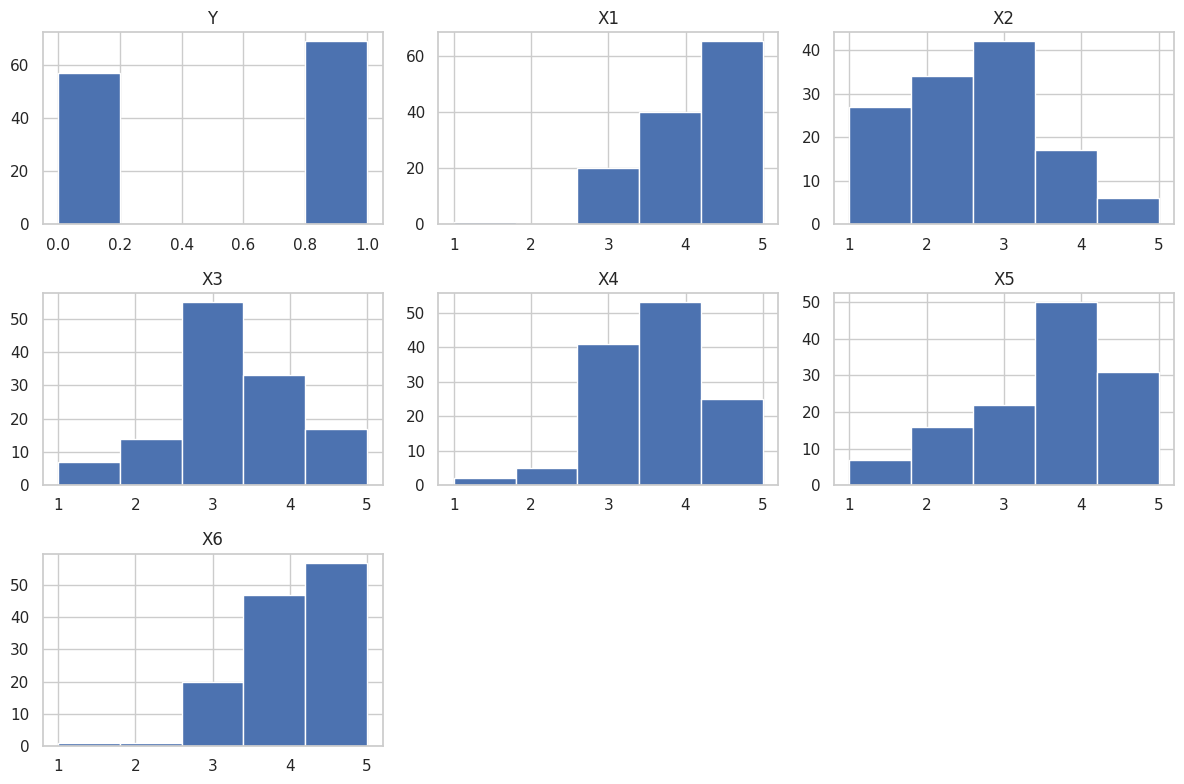

In [9]:
sns.set(style="whitegrid")
#affter leanring basic stats of this data set. we wana plot.
#we will create a hist for every columns to show how survey scores are desributed.
df.hist(bins=5, figsize=(12,8))
plt.tight_layout() #fixes spaces so that plots dont overlap
plt.show()

**Strong signal**

X1 (on-time delivery) is the clearest. Customers who answered 5 were 69% happy, while those who answered 3 or 4 were only 40% happy. The jump is at the very top: “on time” isn’t enough, it has to be a 5.
X5 (courier satisfaction) climbs steadily: 29% → 44% → 45% → 56% → 71%. That clean upward trend is exactly what a useful feature looks like.

**Moderate signal**

X3 (ordered everything I wanted) splits into two groups. Answers 1–3 sit around 45–50% happy, and answers 4–5 sit around 65%.
X6 (app is easy) goes from 30% happy at 3 to about 60% at 4–5. Almost nobody rated it below 3, though.

**Weak or no signal**

X4 (good price) is basically flat from 51% to 60% across the answers most people gave.
X2 (contents as expected) has no pattern at all. It bounces up and down (52, 62, 55, 41, 67). This is your first candidate for a question to drop from the survey.

Ignore the tiny groups. Rows like X4 = 1 (100% happy) or X6 = 2 (0% happy) are based on 1 or 2 customers. That’s noise, not a finding.

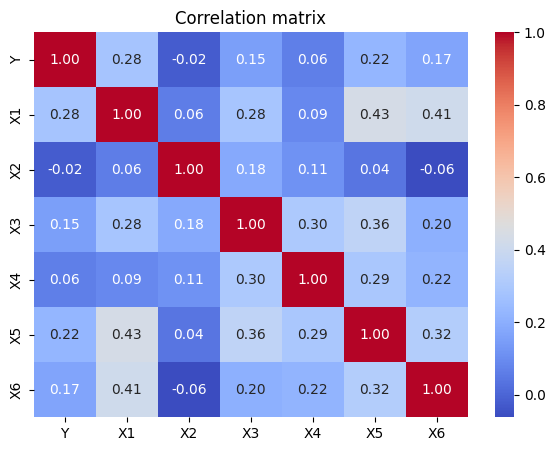

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation matrix")
plt.show()

The biggest overlaps are X1–X5 (0.43) and X1–X6 (0.41). Customers who rate delivery timing highly tend to rate the courier and the app highly too, so these three may partly capture one overall “the service worked” feeling.

Nothing is above 0.5, so no two questions are truly redundant. Each adds at least some information of its own.

X2 is uncorrelated with everything, including Y. It measures something separate from the other questions, and that something doesn’t relate to happiness. That makes it the clearest candidate to drop.

In [10]:
X = df.drop(columns="Y")
y = df["Y"]

In [11]:
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)

In [12]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

models = {
    "Baseline (always guess majority)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression()),
    "Decision Tree": DecisionTreeClassifier(max_depth=3, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=4, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(max_depth=2, random_state=42),
    "SVM": make_pipeline(StandardScaler(), SVC()),
    "Naive Bayes": GaussianNB(),
    "KNN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=7)),
}

results = []
for name, model in models.items():
    scores = cross_val_score(model, X, y, cv=cv, scoring="accuracy")
    results.append((name, scores.mean(), scores.std()))

results_df = pd.DataFrame(results, columns=["Model", "Mean accuracy", "Std"])
results_df.sort_values("Mean accuracy", ascending=False).round(3)

,Model,Mean accuracy,Std
3,Random Forest,0.584,0.081
4,Gradient Boosting,0.583,0.082
2,Decision Tree,0.576,0.074
5,SVM,0.565,0.079
7,KNN,0.560,0.095
1,Logistic Regression,0.552,0.073
6,Naive Bayes,0.551,0.077
0,Baseline (always guess majority),0.548,0.016


Using all six features, the best models reach about 58% accuracy, only slightly above the 55% baseline. Standard deviations (~8%) are larger than the differences between models, so no model is clearly better. This suggests some features add noise rather than signal, motivating feature selection.

In [13]:
from itertools import combinations

features = ["X1", "X2", "X3", "X4", "X5", "X6"]

search_models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression()),
    "Decision Tree": DecisionTreeClassifier(max_depth=3, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=4, random_state=42),
}

subset_results = []
for k in range(1, 7):
    for subset in combinations(features, k):
        for name, model in search_models.items():
            scores = cross_val_score(model, X[list(subset)], y, cv=cv, scoring="accuracy")
            subset_results.append((", ".join(subset), k, name, scores.mean(), scores.std()))

subset_df = pd.DataFrame(subset_results, columns=["Features", "Num features", "Model", "Mean accuracy", "Std"])
subset_df.sort_values("Mean accuracy", ascending=False).head(15).round(3)

,Features,Num features,Model,Mean accuracy,Std
28,"X1, X5",2,Decision Tree,0.667,0.085
92,"X1, X5, X6",3,Random Forest,0.664,0.082
32,"X1, X6",2,Random Forest,0.662,0.063
83,"X1, X3, X6",3,Random Forest,0.653,0.094
1,X1,1,Decision Tree,0.651,0.074
2,X1,1,Random Forest,0.648,0.074
71,"X1, X2, X5",3,Random Forest,0.640,0.083
91,"X1, X5, X6",3,Decision Tree,0.639,0.078
29,"X1, X5",2,Random Forest,0.635,0.080
23,"X1, X3",2,Random Forest,0.633,0.075


X1 appears in all 15 top-performing subsets, confirming it is the most important predictor. X5 and X6 are the most useful additions. Small subsets (2 to 3 features) reach about 66% accuracy, outperforming the full six-feature set (58%). X2 and X4 rarely appear among the top results and are candidates for removal from future surveys.

In [14]:
from sklearn.model_selection import GridSearchCV

cv_tune = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=42)

candidate_sets = [["X1", "X5"], ["X1", "X5", "X6"], ["X1", "X3", "X5", "X6"]]

param_grids = {
    "Decision Tree": (
        DecisionTreeClassifier(random_state=42),
        {"max_depth": [2, 3, 4, 5, None], "min_samples_leaf": [1, 3, 5, 10]},
    ),
    "Random Forest": (
        RandomForestClassifier(n_estimators=100, random_state=42),
        {"max_depth": [2, 3, 4, 6], "min_samples_leaf": [1, 3, 5]},
    ),
}

tune_results = []
for feats in candidate_sets:
    for name, (model, grid) in param_grids.items():
        search = GridSearchCV(model, grid, cv=cv_tune, scoring="accuracy")
        search.fit(X[feats], y)
        best_std = search.cv_results_["std_test_score"][search.best_index_]
        tune_results.append((", ".join(feats), name, search.best_score_, best_std, search.best_params_))

tune_df = pd.DataFrame(tune_results, columns=["Features", "Model", "Best accuracy", "Std", "Best params"])
tune_df.sort_values("Best accuracy", ascending=False).round(3)

,Features,Model,Best accuracy,Std,Best params
0,"X1, X5",Decision Tree,0.686,0.087,"{'max_depth': 3, 'min_samples_leaf': 10}"
2,"X1, X5, X6",Decision Tree,0.668,0.084,"{'max_depth': 5, 'min_samples_leaf': 3}"
3,"X1, X5, X6",Random Forest,0.667,0.084,"{'max_depth': 4, 'min_samples_leaf': 1}"
1,"X1, X5",Random Forest,0.665,0.075,"{'max_depth': 6, 'min_samples_leaf': 3}"
4,"X1, X3, X5, X6",Decision Tree,0.651,0.084,"{'max_depth': None, 'min_samples_leaf': 3}"
5,"X1, X3, X5, X6",Random Forest,0.646,0.083,"{'max_depth': 6, 'min_samples_leaf': 3}"


After tuning, a shallow decision tree (max depth 3, min 10 samples per leaf) using only X1 and X5 achieved the best cross-validated accuracy of 68.6%. Simpler models with fewer features consistently performed best, which suggests the dataset contains limited signal and more complex models tend to overfit.

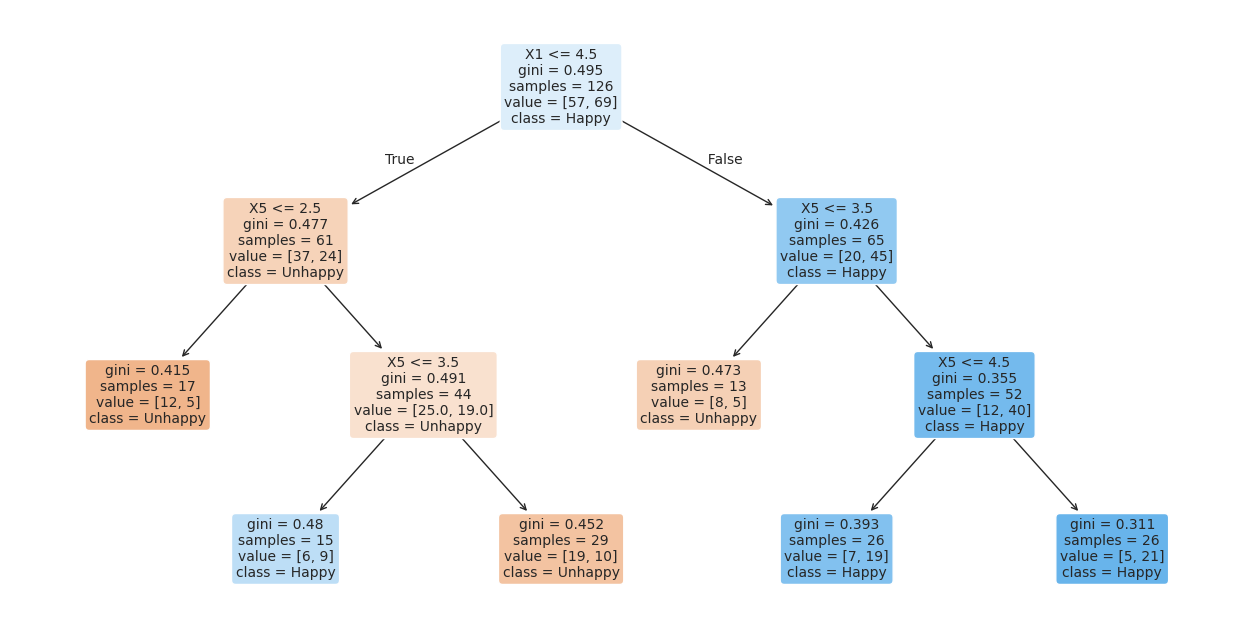

In [15]:
from sklearn.tree import plot_tree

final_features = ["X1", "X5"]
final_model = DecisionTreeClassifier(max_depth=3, min_samples_leaf=10, random_state=42)
final_model.fit(X[final_features], y)

plt.figure(figsize=(16, 8))
plot_tree(final_model, feature_names=final_features, class_names=["Unhappy", "Happy"],
          filled=True, rounded=True, fontsize=10)
plt.show()

Mean accuracy: 0.679
Best fold: 0.840   Worst fold: 0.500
Folds at 73% or above: 32%


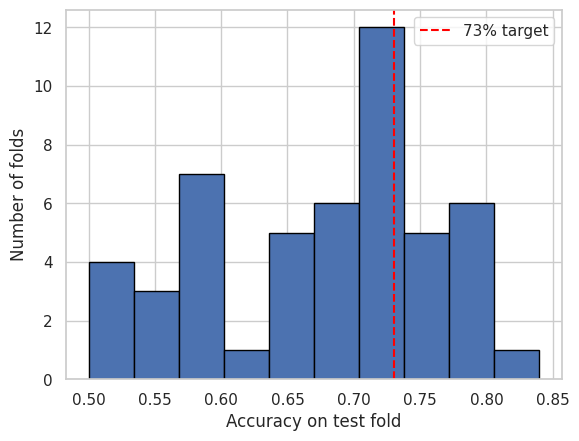

In [16]:
final_scores = cross_val_score(final_model, X[final_features], y, cv=cv, scoring="accuracy")

print(f"Mean accuracy: {final_scores.mean():.3f}")
print(f"Best fold: {final_scores.max():.3f}   Worst fold: {final_scores.min():.3f}")
print(f"Folds at 73% or above: {(final_scores >= 0.73).mean():.0%}")

plt.hist(final_scores, bins=10, edgecolor="black")
plt.axvline(0.73, color="red", linestyle="--", label="73% target")
plt.xlabel("Accuracy on test fold")
plt.ylabel("Number of folds")
plt.legend()
plt.show()

Across 50 cross-validation folds, accuracy ranged from 50% to 84%, with 32% of folds at or above the 73% target. With only 126 samples, a single train/test split is highly unreliable. The mean of 67.9% is a more trustworthy estimate of performance on unseen data than any single split.

In [17]:
simple_model = DecisionTreeClassifier(max_depth=2, min_samples_leaf=10, random_state=42)
simple_scores = cross_val_score(simple_model, X[final_features], y, cv=cv, scoring="accuracy")
print(f"Depth 2: {simple_scores.mean():.3f} ± {simple_scores.std():.3f}")
print(f"Depth 3: {final_scores.mean():.3f} ± {final_scores.std():.3f}")

Depth 2: 0.666 ± 0.080
Depth 3: 0.679 ± 0.088


**Conclusions**

Model performance
The final model is a depth-2 decision tree using two questions (X1 and X5). Across 50 cross-validation folds it averaged about 67% accuracy, compared with a 55% baseline. Individual splits ranged from 50% to 84%, and about a third of them cleared 73%. With only 126 responses, I focused on an averaged estimate instead of a single split, since that should better reflect performance on the private test set.

**Most important questions**

X1 (on-time delivery) is the strongest predictor and appeared in every top-performing feature subset. X5 (courier satisfaction) adds the most on top of it. Using just these two outperformed using all six (58%).

**Survey recommendations**

Keep X1 and X5. They drive most of the predictive power.
X2 (contents as expected) can be removed. It showed no relationship with happiness or with any other question.
X4 (price) can likely be removed. It had almost no relationship with happiness.
X3 and X6 added small, inconsistent gains. They could be kept for operational insight, but they aren’t needed for prediction.

**Business takeaway**

Happiness depends mostly on the delivery experience. Customers are happy when the order arrives fully on time and the courier interaction goes well. Price and order contents matter much less. Improving delivery timeliness and courier quality is likely the most effective way to raise satisfaction.

**Next steps**

More survey responses would be the biggest improvement, since the small sample limits how reliably any model can be evaluated.

How can I make a better model with higher accuracy. Can I drop the least impactful variables? (X2, X4)
